## Step 1: imports and settings

In [46]:
import os                                         # to check whether saved files exist
import random
import torch
import matplotlib.pyplot as plt
from captcha.image import ImageCaptcha
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

CHARSET = "23456789ABCDEFGHJKLMNPQRSTUVWXYZ"
LENGTH = 5

## Step 2:  helper functions

In [47]:

def random_text():
    return "".join(random.choice(CHARSET) for _ in range(LENGTH))

def encode(text):
    return torch.tensor([CHARSET.index(c) for c in text], dtype=torch.long)

def decode(tensor):
    return "".join(CHARSET[int(n)] for n in tensor)

for _ in range(1000):
    t = random_text()
    if decode(encode(t)) != t:
        print(t)

## Step 3:  Dataset

In [48]:

class CaptchaDataset(Dataset):
    def __init__(self, size):
        self.size = size
        self.generator = ImageCaptcha(width=160, height=60)
        self.to_tensor = transforms.ToTensor()

    def __len__(self):
        return self.size

    def __getitem__(self, idx):
        text = random_text()
        img = self.generator.generate_image(text).convert("L")
        return self.to_tensor(img), encode(text)

## Step 4: Checks

torch.Size([64, 1, 60, 160]) torch.Size([64, 5])


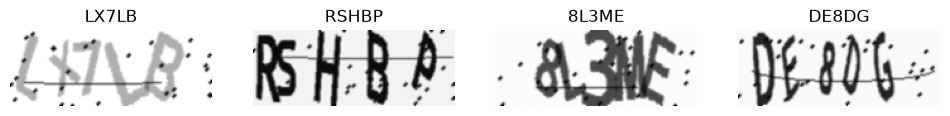

In [49]:

dataset = CaptchaDataset(10000)
loader = DataLoader(dataset, batch_size=64, num_workers=0)
xb, yb = next(iter(loader))
print(xb.shape, yb.shape)

fig, axes = plt.subplots(1, 4, figsize=(12, 2))
for i in range(4):
    axes[i].imshow(xb[i].squeeze(), cmap="gray")
    axes[i].set_title(decode(yb[i]))
    axes[i].axis("off")
plt.show()

## Step 5: Building model

In [50]:
import torch.nn as nn
import torch.nn.functional as F

class CaptchaCNN(nn.Module):
    def __init__(self):
        super().__init__()

        # ---- shared body: 3 blocks of conv → batchnorm → relu → pool ----
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)    # 1 channel in → 32 out
        self.bn1   = nn.BatchNorm2d(32)                             # rescale conv1's 32 channels

        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)   # 32 → 64
        self.bn2   = nn.BatchNorm2d(64)                             # rescale conv2's 64 channels

        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)  # 64 → 128
        self.bn3   = nn.BatchNorm2d(128)                            # rescale conv3's 128 channels

        self.pool  = nn.MaxPool2d(2)                                # halves height and width (reused)

        # ---- 5 heads: one Linear per character position ----
        self.heads = nn.ModuleList(
            [nn.Linear(128 * 7 * 20, len(CHARSET))                  # 17,920 features → 32 scores
             for _ in range(LENGTH)]                                # × 5 positions
        )

    def forward(self, x):                                           # x: (B, 1, 60, 160)
        x = self.pool(F.relu(self.bn1(self.conv1(x))))              # → (B, 32, 30, 80)
        x = self.pool(F.relu(self.bn2(self.conv2(x))))              # → (B, 64, 15, 40)
        x = self.pool(F.relu(self.bn3(self.conv3(x))))              # → (B, 128, 7, 20)
        x = x.flatten(1)                                            # → (B, 17920)
        return [head(x) for head in self.heads]                     # → 5 × (B, 32)

In [51]:
model = CaptchaCNN()
outs = model(xb)
print(len(outs), outs[0].shape) #here xb is one batch, meaning 64 images, and the 32 means 32 characters so thinkg about scores per character for 64 images

5 torch.Size([64, 32])


## Step 6: Training

### Setup — run once
Creates a fresh, untrained model, loss function, and optimizer.
Kept separate from the training loop: re-running this cell **resets the model to zero**.

In [52]:
device = "mps"                                    # use the Mac's GPU
model = CaptchaCNN().to(device)                   # empty model, same architecture
loss_fn = nn.CrossEntropyLoss()                   # measures how wrong a classification is
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)   # updates all weights

if os.path.exists("captcha_cnn.pt"):              # trained weights saved → continue from them
    model.load_state_dict(torch.load("captcha_cnn.pt"))
    print("Loaded saved model")
else:                                             # first time → start from zero
    print("Starting a fresh model")

Loaded saved model


### Training loop — run as many times as needed
Each run **continues** training the same model from where it stopped.
If the setup were in this cell too, every run would start a brand-new model from scratch.

In [53]:
TRAIN = False                                     # set True only when you want to train

if TRAIN:
    model.train()                                 # training mode (needed after evaluation)
    for epoch in range(10):                       # full passes over the data
        total_loss = 0                            # running sum of batch losses
        for xb, yb in loader:                     # one batch: 64 CAPTCHAs + labels
            xb = xb.to(device)                    # images → GPU  (64, 1, 60, 160)
            yb = yb.to(device)                    # labels → GPU  (64, 5)
            outs = model(xb)                      # 5 × (64, 32)
            loss = sum(loss_fn(outs[i], yb[:, i]) # batch loss = sum of the 5
                       for i in range(LENGTH))    #   per-position losses
            optimizer.zero_grad()                 # clear old gradients
            loss.backward()                       # compute new gradients
            optimizer.step()                      # update the weights
            total_loss += loss.item()             # add this batch's loss
        print(f"Epoch {epoch}: avg loss {total_loss / len(loader):.3f}")

    torch.save(model.state_dict(), "captcha_cnn.pt")   # save after every training run
    print("Model saved")
else:
    print("Training skipped (TRAIN = False)")

Training skipped (TRAIN = False)


## Step 7: Evaluation

### building the fixed test set (run once)

In [54]:
if os.path.exists("test_set.pt"):                 # already built → nothing to do
    print("Test set already exists")
else:                                             # first time only → build and save
    random.seed(42)                               # same "random" CAPTCHAs every run
    gen = CaptchaDataset(2000)                    # a FACTORY: gen[i] draws a new CAPTCHA on demand
    pairs = [gen[i] for i in range(2000)]         # 2000 (image, label) pairs
    X_test = torch.stack([x for x, y in pairs])   # (2000, 1, 60, 160)
    Y_test = torch.stack([y for x, y in pairs])   # (2000, 5); row k matches image k
    torch.save((X_test, Y_test), "test_set.pt")   # save → same test set every time
    print("Test set built and saved")

Test set already exists


### Actual evaluation

In [55]:
from torch.utils.data import TensorDataset           # needed for TensorDataset

X_test, y_test = torch.load("test_set.pt")           # same 2000 test CAPTCHAs every time
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=64)

model.eval()                                         # testing mode (BatchNorm uses learned stats)
char_correct, seq_correct, total = 0, 0, 0
with torch.no_grad():                                # no gradients, just predicting
    for xb, yb in test_loader:
        xb = xb.to(device)                           # images → GPU   (B, 1, 60, 160)
        yb = yb.to(device)                           # labels → GPU   (B, 5)
        outs = model(xb)                             # 5 × (B, 32)
        preds = torch.stack([o.argmax(1) for o in outs], dim=1)   # (B, 5) predicted chars
        matches = preds == yb                        # (B, 5) True where a char is right

        char_correct += matches.sum().item()         # count every correct character
        seq_correct  += matches.all(dim=1).sum().item()   # count CAPTCHAs with all 5 right
        total += yb.size(0)                          # images in this batch

print(f"Per-character accuracy: {char_correct / (total * LENGTH):.2%}")
print(f"Solve rate (all 5 right): {seq_correct / total:.2%}")

Per-character accuracy: 86.93%
Solve rate (all 5 right): 53.65%


## Step 8: Learning-rate sweep

### validation set

In [60]:
from torch.utils.data import TensorDataset        # wraps fixed tensors into a Dataset

if os.path.exists("val_set.pt"):                  # already built → nothing to do
    print("Validation set already exists")
else:                                             # first time only → build and save
    random.seed(7)                                # DIFFERENT seed than the test set (42)
    gen = CaptchaDataset(1000)                    # factory: gen[i] draws a new CAPTCHA
    pairs = [gen[i] for i in range(1000)]         # 1000 (image, label) pairs
    X_val = torch.stack([x for x, y in pairs])    # (1000, 1, 60, 160)
    Y_val = torch.stack([y for x, y in pairs])    # (1000, 5)
    torch.save((X_val, Y_val), "val_set.pt")      # save → same val set every time
    print("Validation set built and saved")

X_val, Y_val = torch.load("val_set.pt")           # load it either way
val_loader = DataLoader(TensorDataset(X_val, Y_val), batch_size=64)

Validation set already exists


### evaluation as a reusable function

In [61]:
def evaluate(m, data_loader):                     # m = any model, data_loader = val or test
    m.eval()                                      # testing mode
    char_correct, seq_correct, total = 0, 0, 0
    with torch.no_grad():                         # no gradients, just predicting
        for xb, yb in data_loader:
            xb = xb.to(device)                    # images → GPU
            yb = yb.to(device)                    # labels → GPU
            outs = m(xb)                          # 5 × (B, 32)
            preds = torch.stack([o.argmax(1) for o in outs], dim=1)   # (B, 5)
            matches = preds == yb                 # (B, 5) True/False
            char_correct += matches.sum().item()              # correct characters
            seq_correct  += matches.all(dim=1).sum().item()   # fully solved CAPTCHAs
            total += yb.size(0)                   # images in this batch
    return char_correct / (total * LENGTH), seq_correct / total   # (char acc, solve rate)

### the sweep

In [ ]:
SWEEP = False                                     # set True only when you want to run it
LRS = [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1, 3e-1, 1]   # ×3 steps (Andrew Ng)
SWEEP_EPOCHS = 3                                  # short runs: enough to compare
results = {}                                      # lr → (char acc, solve rate)

if SWEEP:
    for lr in LRS:
        m = CaptchaCNN().to(device)               # FRESH model for every lr (fair comparison)
        opt = torch.optim.Adam(m.parameters(), lr=lr)   # its own optimizer
        m.train()                                 # training mode
        for epoch in range(SWEEP_EPOCHS):
            total_loss = 0
            for xb, yb in loader:                 # same training data as before
                xb = xb.to(device)
                yb = yb.to(device)
                outs = m(xb)                      # 5 × (64, 32)
                loss = sum(loss_fn(outs[i], yb[:, i]) for i in range(LENGTH))
                opt.zero_grad()                   # clear old gradients
                loss.backward()                   # compute new gradients
                opt.step()                        # update this model's weights
                total_loss += loss.item()

        char_acc, solve = evaluate(m, val_loader) # score on VALIDATION, not test
        results[lr] = (char_acc, solve)
        print(f"lr={lr:<7} loss {total_loss / len(loader):.3f}  "
              f"char {char_acc:.2%}  solve {solve:.2%}")
else:
    print("Sweep skipped (SWEEP = False)")

lr=0.0001  loss 7.847  char 62.74%  solve 11.30%
lr=0.0003  loss 5.502  char 71.72%  solve 22.00%
lr=0.001   loss 6.698  char 60.52%  solve 10.40%
lr=0.003   loss 7.265  char 24.82%  solve 0.50%
lr=0.01    loss 15.353  char 23.28%  solve 0.10%
lr=0.03    loss 17.350  char 3.20%  solve 0.00%
lr=0.1     loss 17.404  char 3.18%  solve 0.00%
lr=0.3     loss 17.548  char 2.74%  solve 0.00%
lr=1       loss 17.974  char 3.26%  solve 0.00%


In [ ]:
SWEEP = False                                     # set True only when you want to run it
LRS = [1e-4, 3e-4, 1e-3, 3e-3]
SWEEP_EPOCHS = 10

results = {}                                      # lr → (char acc, solve rate)

if SWEEP:
    for lr in LRS:
        m = CaptchaCNN().to(device)               # FRESH model for every lr (fair comparison)
        opt = torch.optim.Adam(m.parameters(), lr=lr)   # its own optimizer
        m.train()                                 # training mode
        for epoch in range(SWEEP_EPOCHS):
            total_loss = 0
            for xb, yb in loader:                 # same training data as before
                xb = xb.to(device)
                yb = yb.to(device)
                outs = m(xb)                      # 5 × (64, 32)
                loss = sum(loss_fn(outs[i], yb[:, i]) for i in range(LENGTH))
                opt.zero_grad()                   # clear old gradients
                loss.backward()                   # compute new gradients
                opt.step()                        # update this model's weights
                total_loss += loss.item()

        char_acc, solve = evaluate(m, val_loader) # score on VALIDATION, not test
        results[lr] = (char_acc, solve)
        print(f"lr={lr:<7} loss {total_loss / len(loader):.3f}  "
              f"char {char_acc:.2%}  solve {solve:.2%}")
else:
    print("Sweep skipped (SWEEP = False)") 

lr=0.0001  loss 3.777  char 80.66%  solve 39.10%
lr=0.0003  loss 3.063  char 82.88%  solve 42.70%
lr=0.001   loss 2.813  char 84.56%  solve 48.10%
lr=0.003   loss 2.963  char 72.14%  solve 19.30%


## Step 9: Final Training

In [ ]:
TRAIN = False                                      # set True only when you want to train
LR = 1e-4                                       # chosen by the sweep (stage 2); later 3e-4
EPOCHS = 10                                       # epochs per run

for g in optimizer.param_groups:                  # apply LR to the real model's optimizer
    g["lr"] = LR

if TRAIN:
    _, best_solve = evaluate(model, val_loader)   # validation score BEFORE training
    print(f"Before: solve {best_solve:.2%}")

    model.train()                                 # training mode (evaluate switched it off)
    for epoch in range(EPOCHS):                   # full passes over the data
        total_loss = 0                            # running sum of batch losses
        for xb, yb in loader:                     # one batch: 64 CAPTCHAs + labels
            xb = xb.to(device)                    # images → GPU  (64, 1, 60, 160)
            yb = yb.to(device)                    # labels → GPU  (64, 5)
            outs = model(xb)                      # 5 × (64, 32)
            loss = sum(loss_fn(outs[i], yb[:, i]) # batch loss = sum of the 5
                       for i in range(LENGTH))    #   per-position losses
            optimizer.zero_grad()                 # clear old gradients
            loss.backward()                       # compute new gradients
            optimizer.step()                      # update the weights
            total_loss += loss.item()             # add this batch's loss
        print(f"Epoch {epoch}: avg loss {total_loss / len(loader):.3f}")

    char_acc, solve = evaluate(model, val_loader) # validation score AFTER training
    print(f"After:  char {char_acc:.2%}  solve {solve:.2%}")

    if solve > best_solve:                        # better → keep it
        torch.save(model.state_dict(), "captcha_cnn.pt")
        print("Better → model saved")
    else:                                         # worse → go back to the saved model
        model.load_state_dict(torch.load("captcha_cnn.pt"))
        print("Not better → kept the old model")
else:
    print("Training skipped (TRAIN = False)")

Before: solve 78.80%
Epoch 0: avg loss 0.861
Epoch 1: avg loss 0.881
Epoch 2: avg loss 0.877
Epoch 3: avg loss 0.839
Epoch 4: avg loss 0.887
Epoch 5: avg loss 0.844
Epoch 6: avg loss 0.844
Epoch 7: avg loss 0.829
Epoch 8: avg loss 0.898
Epoch 9: avg loss 0.853
After:  char 95.40%  solve 81.20%
Better → model saved


In [70]:
char_acc, solve = evaluate(model, test_loader)     # FINAL score, test set (used once)
print(f"TEST → char {char_acc:.2%}  solve {solve:.2%}")

TEST → char 95.12%  solve 80.25%
